This portion of the project is looking for how much wagering the machines likely missed while they were down, and where it mattered most.

In Part 3A, we measured how long active casino machines were unavailable from January through June 2025. Each row represents one machine during one hour. We calculated downtime by subtracting the machine’s available seconds from 3,600. For example, a machine available for 45 minutes contributed 15 minutes of downtime. Across all machines, downtime totaled 5,021.08 machine-hours. The next step uses wagering activity during comparable hours to estimate how much play the machines may have missed.

In [7]:
from pathlib import Path
import pandas as pd

# Each row represents one machine during one hour.
file_path = Path("/content/dashboard-royale/data/5_optional/machine_hour.csv.gz")
hours = pd.read_csv(file_path, usecols=[
    "machine_id", "gaming_date", "local_hour", "active",
    "available_seconds", "coin_in_cents",
])

# Count only hours when the machine was active on the floor.
hours = hours.loc[hours["active"]].copy()

# A machine can be available for anywhere from 0 to 3,600 seconds per hour.
assert hours["available_seconds"].between(0, 3600).all()
hours["downtime_minutes"] = (3600 - hours["available_seconds"]) / 60

print(f"Active machine-hour records: {len(hours):,}")
print(f"Total downtime: {hours['downtime_minutes'].sum() / 60:,.2f} machine-hours")

# Show five rows with actual downtime so you can inspect the calculation.
display(hours.loc[hours["downtime_minutes"] > 0, [
    "machine_id", "gaming_date", "local_hour", "available_seconds", "downtime_minutes"
]].head())

Active machine-hour records: 1,321,908
Total downtime: 5,021.08 machine-hours


,machine_id,gaming_date,local_hour,available_seconds,downtime_minutes
1133,M-1001,2025-02-17,11,2372,20.466667
1134,M-1001,2025-02-17,12,0,60.000000
1135,M-1001,2025-02-17,13,106,58.233333
1234,M-1001,2025-02-21,16,2635,16.083333
1235,M-1001,2025-02-21,17,0,60.000000


Part 3B — Summary for your Colab text cell: We estimated missed wagers by comparing each machine’s downtime with its wagering activity during fully available hours at the same time of day. We separated weekdays from weekends to account for differences in demand. Multiplying each machine’s usual hourly wagering rate by the time it was unavailable gave an estimated $1.09 million in missed machine wagers from January through June 2025.

In [8]:
# Use the gaming date to distinguish weekdays from weekends.
# pandas numbers Monday as 0 and Sunday as 6.
hours["weekend"] = pd.to_datetime(hours["gaming_date"]).dt.dayofweek >= 5
hours["wager_usd"] = hours["coin_in_cents"] / 100

# Fully available hours show how much play the machine normally receives.
# An available hour with zero wagers still counts when calculating the average.
healthy = hours.loc[hours["available_seconds"] == 3600]
match_columns = ["machine_id", "local_hour", "weekend"]

normal_rates = healthy.groupby(match_columns).agg(
    usual_wagers_per_hour=("wager_usd", "mean"),
    comparison_hours=("wager_usd", "size"),
)

# Attach the matching rate to every hour with some downtime.
outages = hours.loc[hours["downtime_minutes"] > 0].copy()
outages = outages.join(normal_rates, on=match_columns)

# If fewer than three matching hours exist, use that machine's average
# across all of its fully available hours.
machine_average = healthy.groupby("machine_id")["wager_usd"].mean()
matched_rate = outages["usual_wagers_per_hour"].where(outages["comparison_hours"] >= 3)
outages["estimated_rate"] = matched_rate.fillna(outages["machine_id"].map(machine_average))

assert outages["estimated_rate"].notna().all(), "An outage has no comparison rate."

# Apply the hourly rate only to the portion of the hour that was lost.
outages["missed_wagers_usd"] = (
    outages["downtime_minutes"] / 60 * outages["estimated_rate"]
)

print(f"Machine-hour records with downtime: {len(outages):,}")
print(f"Records using the fallback rate: {matched_rate.isna().sum():,}")
print(f"Estimated missed machine wagers: ${outages['missed_wagers_usd'].sum():,.2f}")

display(outages[[
    "machine_id", "gaming_date", "local_hour", "downtime_minutes",
    "comparison_hours", "estimated_rate", "missed_wagers_usd"
]].head().round(2))

Machine-hour records with downtime: 6,218
Records using the fallback rate: 0
Estimated missed machine wagers: $1,085,352.23


,machine_id,gaming_date,local_hour,downtime_minutes,comparison_hours,estimated_rate,missed_wagers_usd
1133,M-1001,2025-02-17,11,20.47,127,218.47,74.52
1134,M-1001,2025-02-17,12,60.00,127,203.86,203.86
1135,M-1001,2025-02-17,13,58.23,127,257.07,249.50
1234,M-1001,2025-02-21,16,16.08,127,278.18,74.57
1235,M-1001,2025-02-21,17,60.00,127,311.21,311.21


We grouped machine downtime by gaming month and local hour to identify when the most wagering was missed. May had the largest monthly total, with an estimated 215,601.95 in missed machine wagers. Across all six months, the 9–10 p.m. window accounted for the largest hourly total at 98,971.17. The following hour had more downtime but less estimated missed wagering, showing why both outage duration and typical demand matter when prioritizing repairs. These estimates describe wagering that individual machines could have handled. Some guests may have continued playing elsewhere on the casino floor.

In [9]:
import numpy as np

# Use the casino's gaming date to assign each outage record to a month.
outages["month"] = pd.to_datetime(outages["gaming_date"]).dt.to_period("M")
outages["downtime_hours"] = outages["downtime_minutes"] / 60

# Each table summarizes the same outages from a different perspective.
columns = ["downtime_hours", "missed_wagers_usd"]
by_month = outages.groupby("month")[columns].sum()
by_hour = outages.groupby("local_hour")[columns].sum()

# Calculate the average wagering impact of one machine-hour of downtime.
for table in [by_month, by_hour]:
    table["missed_wagers_per_down_hour"] = (
        table["missed_wagers_usd"] / table["downtime_hours"]
    )

# Both breakdowns should independently reproduce the original 3B total.
total_missed = outages["missed_wagers_usd"].sum()
for table in [by_month, by_hour]:
    assert np.isclose(table["missed_wagers_usd"].sum(), total_missed,
                      rtol=0, atol=0.01)

print("Monthly totals")
display(by_month.round(2))

print("Top five local hours by estimated missed wagers")
display(by_hour.nlargest(5, "missed_wagers_usd").round(2))

Monthly totals


,downtime_hours,missed_wagers_usd,missed_wagers_per_down_hour
month,,,
2025-01,866.54,194477.46,224.43
2025-02,772.49,167408.94,216.71
2025-03,979.20,211735.36,216.23
2025-04,755.07,168056.26,222.57
2025-05,1017.31,215601.95,211.93
2025-06,630.47,128072.27,203.14


Top five local hours by estimated missed wagers


,downtime_hours,missed_wagers_usd,missed_wagers_per_down_hour
local_hour,,,
21,292.91,98971.17,337.89
20,263.33,92799.38,352.40
22,306.64,92264.80,300.89
19,233.96,81840.97,349.81
23,298.45,74953.29,251.14


We grouped estimated missed wagers by gaming month and local hour. The heatmap shows when downtime had the greatest estimated impact on wagering and whether high-impact hours recurred across months. Each cell represents the combined estimate for all machines during that month and hour. Some guests may have switched to other machines, so the casino-wide impact could be smaller.

Once this runs, you have the three pieces needed to present Part 3: 5,021.08 measured downtime hours, $1.09 million in estimated missed machine wagers, and a figure showing when that impact occurred.

<>:32: SyntaxWarning: invalid escape sequence '\$'
<>:32: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_561/406476287.py:32: SyntaxWarning: invalid escape sequence '\$'
  print(f"Estimated missed wagers in that cell: \${peak_value:,.2f}".replace("\\$", "$"))


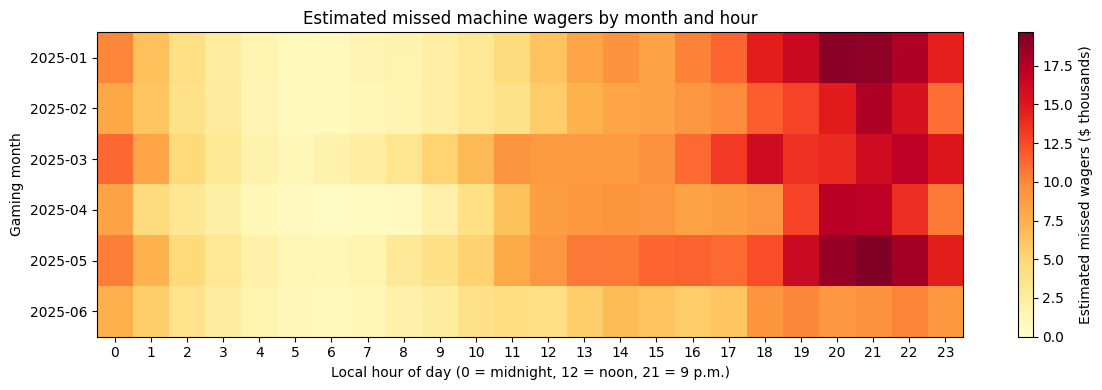

Highest cell: 2025-05, hour starting at 21:00 local time
Estimated missed wagers in that cell: $19,647.73


In [10]:
import matplotlib.pyplot as plt

# Each cell holds the estimated missed wagers for one month and local hour.
heatmap = outages.pivot_table(
    index="month",
    columns="local_hour",
    values="missed_wagers_usd",
    aggfunc="sum",
    fill_value=0,
).reindex(columns=range(24), fill_value=0)

# Check that the heatmap accounts for all estimated missed wagers from 3B.
assert np.isclose(heatmap.to_numpy().sum(), total_missed, rtol=0, atol=0.01)

fig, ax = plt.subplots(figsize=(12, 4))
image = ax.imshow(heatmap / 1000, aspect="auto", cmap="YlOrRd", vmin=0)

ax.set_xticks(range(24), labels=range(24))
ax.set_yticks(range(len(heatmap)), labels=heatmap.index.astype(str))
ax.set_xlabel("Local hour of day (0 = midnight, 12 = noon, 21 = 9 p.m.)")
ax.set_ylabel("Gaming month")
ax.set_title("Estimated missed machine wagers by month and hour")
fig.colorbar(image, ax=ax, label="Estimated missed wagers ($ thousands)")

plt.tight_layout()
plt.show()

# Identify the peak directly from the data.
peak_month, peak_hour = heatmap.stack().idxmax()
peak_value = heatmap.loc[peak_month, peak_hour]
print(f"Highest cell: {peak_month}, hour starting at {peak_hour:02d}:00 local time")
print(f"Estimated missed wagers in that cell: \${peak_value:,.2f}".replace("\\$", "$"))

Across the six-month period, machines were unavailable for 5,021.08 machine-hours. We estimated that those machines could have handled approximately 1.09 million in additional wagers. The casino-wide impact depends on how much play shifted to working machines. For example, if half of those wagers occurred elsewhere on the floor, the estimated missed wagering would fall to about 543,000. These percentages are scenarios, and the dollar amounts measure wager volume rather than casino profit.

In [11]:
# Reuse the missed-wager estimate from Part 3B.
missed_machine_wagers = outages["missed_wagers_usd"].sum()

# Assume different shares of those wagers moved to other machines.
scenarios = pd.DataFrame({"Share wagered elsewhere": [0.0, 0.5, 0.9]})
scenarios["Estimated missed casino-wide wagers ($)"] = (
    missed_machine_wagers * (1 - scenarios["Share wagered elsewhere"])
)

display(scenarios.style.format({
    "Share wagered elsewhere": "{:.0%}",
    "Estimated missed casino-wide wagers ($)": "\${:,.2f}",
}))

<>:12: SyntaxWarning: invalid escape sequence '\$'
<>:12: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_561/2865515566.py:12: SyntaxWarning: invalid escape sequence '\$'
  "Estimated missed casino-wide wagers ($)": "\${:,.2f}",


,Share wagered elsewhere,Estimated missed casino-wide wagers ($)
0,0%,"\$1,085,352.23"
1,50%,"\$542,676.12"
2,90%,"\$108,535.22"
